# 03. Качество основных полей и доступность к C40

Проверяем отдельно замечания к полному сообщению и каноническую часть до QNH.
Исходные тексты, строки и прежние флаги качества сохраняются. Проверенный
префикс не означает исправленное или полностью валидное сообщение.

Задержки 0, 5, 10 и 15 минут — **предположения для анализа чувствительности**.
В сохраненном ответе IEM имеются station, valid и metar, но нет времени
фактического получения сообщения. Архив не подтверждает историческую доступность.
[Описание IEM](https://mesonet.agron.iastate.edu/info/datasets/metar.html) ·
[API IEM](https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py?help=) ·
[Предыдущий ноутбук](02_metar_decoding.ipynb)


In [ ]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTMLЫ
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
from decode_metar import decode, split_sections, PRESSURE, TEMPERATURE
reports = pd.read_parquet(DATA / '04_decoded_reports.parquet')
events = pd.read_parquet(DATA / '03_pilot_matches.parquet')
protected = {p:sha(p) for p in [DATA/'04_decoded_reports.parquet', DATA/'04_pilot_features.parquet', DATA/'03_pilot_matches.parquet']}
fields = [f for f in reports.columns if f.startswith(('wind_','visibility_','cloud_',
    'present_weather_','qnh_','vertical_visibility_')) or f in ['temperature_token',
    'temperature_c','dewpoint_c','cavok','gust_group_reported',
    'cumulonimbus_reported','towering_cumulus_reported']]
def same(a,b):
    if a is None or (isinstance(a,float) and np.isnan(a)):
        return b is None or (isinstance(b,float) and np.isnan(b))
    return a == b
def audit_core(raw,station,stamp,original):
    observed = split_sections(raw)[0]
    tokens = observed.split()
    pressure = [i for i,t in enumerate(tokens) if PRESSURE.fullmatch(t)]
    if len(pressure) != 1:
        return False, '', 'qnh_missing_or_multiple'
    end = pressure[0]
    temperatures = [t for t in tokens[:end] if TEMPERATURE.fullmatch(t)]
    if len(temperatures) != 1:
        return False, '', 'temperature_missing_or_multiple'
    prefix = ' '.join(tokens[:end+1])
    checked = decode(prefix,station,stamp.to_pydatetime())
    changed = [f for f in fields if not same(original[f],checked[f])]
    ok = checked['decoded_candidate'] and not changed
    return ok, prefix, ('value_disagreement:'+','.join(changed) if changed else checked['decode_issues'])
audits = [audit_core(row.metar,row.station,row.metar_utc,row._asdict())
          for row in reports.itertuples(index=False)]
reports[['core_validated','core_prefix','core_issues']] = pd.DataFrame(audits,index=reports.index)
assert len(reports)==9223 and reports.metar_id.is_unique
residual = reports.loc[~reports.decoded_candidate,
    ['metar_id','station','metar_utc','metar','core_prefix','core_validated','core_issues']]
readable_table(residual)
residual.to_csv(R/'06_core_residual_audit.csv',index=False)
display(reports.groupby(['decoded_candidate','core_validated']).size().rename('reports').reset_index())


metar_id,station,metar_utc,metar,core_prefix,core_validated,core_issues
dd288f08c26c9270b99500b582e1872b684f608a5064fae21670c14bc2028770,EGCC,2019-01-22 10:50:00+00:00,EGCC 221050Z VRB03KT 9999 BKN015CB 02/00 Q1000 2000 SHSN TSGS BKN004,EGCC 221050Z VRB03KT 9999 BKN015CB 02/00 Q1000,True,
71687e2f07947e62198dae234e7f901d05b328c01a761ca7662fb05061d74cbd,EGLL,2019-01-16 15:20:00+00:00,EGLL 161520Z AUTO 23009KT 8000 -RA SCT014/// SCT018/// BKN023/// //////CB 10/08 Q1001 3000 SHRA TEMPO BKN014,EGLL 161520Z AUTO 23009KT 8000 -RA SCT014/// SCT018/// BKN023/// //////CB 10/08 Q1001,True,
1c3555165071f9f7ba09339ae088bd17a3454de213a70ec66d0ea91a0c477761,LFPG,2019-01-07 19:00:00+00:00,LFPG 071900Z 23010KT 8000 FEW007 BKN024 TEMPO BKN007,,False,qnh_missing_or_multiple
ee2b29c5c8f7ced489343c3e7b069073da5e6d0a8ef223f27db7b4e126279d4d,LFPG,2019-01-30 00:30:00+00:00,LFPG 300030Z 34008KT 1800 SN BR FEW003 BKN005 BKN012 00/M00 Q0989 ///// TEMPO 0800 SN BKN003,LFPG 300030Z 34008KT 1800 SN BR FEW003 BKN005 BKN012 00/M00 Q0989,True,
4f283ab6656bed4e18b569b69450e0614ca95dc1f76dd9617048eca8f6c9a2bc,LFPG,2019-01-30 03:00:00+00:00,LFPG 300300Z 31010KT 1300 R27L/1900D R09R/1900U R26R/P2000 R08L/P2000 R26L/P2000 R08R/P2000 R27R/P2000 R09L/P2000 SN FEW002 BKN003 00/M00 Q0990 ///// TEMPO 0800 SN BKN003,LFPG 300300Z 31010KT 1300 R27L/1900D R09R/1900U R26R/P2000 R08L/P2000 R26L/P2000 R08R/P2000 R27R/P2000 R09L/P2000 SN FEW002 BKN003 00/M00 Q0990,True,
83c3abe5abdecaeca70126c3ec6988937ea5576a00e3e13cf6bcf3c2d9bfecae,LFPG,2019-01-30 04:00:00+00:00,LFPG 300400Z 31014KT 2000 -SN BR FEW003 BKN004 00/M00 Q0991 R26/5940 R27L/59//42 TEMPO 0800 SN BKN003,LFPG 300400Z 31014KT 2000 -SN BR FEW003 BKN004 00/M00 Q0991,True,
7618fae690c4a4f69da3f1dfd671774d228c3fe901901a5a8a762c03c9c66ce5,LFPG,2019-01-30 04:30:00+00:00,LFPG 300430Z 32023KT 3000 -SN BR SCT006 BKN008 00/00 Q0991 R26/5940 R27L/59//42 R27R/590335 TEMPO 0800 SN BKN003,LFPG 300430Z 32023KT 3000 -SN BR SCT006 BKN008 00/00 Q0991,True,
ab686ef5862c523a38fdbabccf5dabd693478905761da8692fa8c660429d9cfb,LFPG,2019-01-30 05:00:00+00:00,LFPG 300500Z 31020KT 6000 -RASN BKN011 BKN017 01/00 Q0992 R26/5940 R27L/59//42 R27R/590335 TEMPO 0800 SN BKN003,LFPG 300500Z 31020KT 6000 -RASN BKN011 BKN017 01/00 Q0992,True,
46f5abe5dc88bf3dad7081b931c2b0302620782908f5c5e4071f5e616f198b4c,LFPG,2019-01-30 05:30:00+00:00,LFPG 300530Z 30017KT 8000 -RASN BKN016 SCT036 01/M00 Q0993 R26/5940 R27L/59//42 R27R/590335 TEMPO 0800 SN BKN003,LFPG 300530Z 30017KT 8000 -RASN BKN016 SCT036 01/M00 Q0993,True,
dbf88f96fce0458e76c656f28de9a06f8dcaeaecf9bf762f99f776f533621c4c,LFPG,2019-01-30 06:00:00+00:00,LFPG 300600Z 30015KT 9000 BKN010 SCT017 01/00 Q0994 R26/5940 R27L/59//42 R27R/590335 NOSIG,LFPG 300600Z 30015KT 9000 BKN010 SCT017 01/00 Q0994,True,


,decoded_candidate,core_validated,reports
0,False,False,1
1,False,True,9
2,True,True,9213


## Повторный выбор сообщения при предполагаемой задержке

Для каждого C40 выбираем последнее сообщение, для которого время наблюдения
плюс задержка строго меньше C40. Давность считаем от наблюдения, максимум
30, 60 или 90 минут. Сообщения с замечаниями и COR не пропускаем при поиске:
сначала выбираем последнее, затем проверяем качество. Таким образом качество
не вызывает скрытый переход к более старому сообщению. Неоднозначные тексты
на одной временной отметке не дают кандидата. COR остается отдельным сценарием.


In [3]:
rows = []
zero_parts = []
for latency in [0,5,10,15]:
    for (airport,month),part in events.groupby(['airport','month']):
        right = reports.loc[reports.station.eq(airport) & reports.archive_month.eq(month)].copy()
        right['ambiguous'] = right.groupby('metar_utc').metar.transform('nunique').gt(1)
        right = right.drop_duplicates('metar_utc').sort_values('metar_utc')
        right['assumed_available_utc'] = right.metar_utc+pd.Timedelta(minutes=latency)
        joined = pd.merge_asof(part[['source_row','C40_CROSS_TIME','GoA']].sort_values('C40_CROSS_TIME'),
            right[['assumed_available_utc','metar_utc','metar_id','decoded_candidate','core_validated','correction_reported','ambiguous']],
            left_on='C40_CROSS_TIME',right_on='assumed_available_utc',direction='backward',allow_exact_matches=False)
        joined['age'] = (joined.C40_CROSS_TIME-joined.metar_utc).dt.total_seconds()/60
        assert joined.loc[joined.metar_utc.notna(),'age'].gt(latency).all()
        if latency==0:
            zero_parts.append(joined[['source_row','metar_utc']])
        for limit in [30,60,90]:
            timely = joined.age.le(limit) & ~joined.ambiguous.eq(True)
            for quality in ['decoded_candidate','core_validated']:
                for exclude_cor in [False,True]:
                    candidate = timely & joined[quality].eq(True)
                    if exclude_cor:
                        candidate &= ~joined.correction_reported.eq(True)
                    for label in [False,True]:
                        group = joined.GoA.eq(label)
                        rows.append(dict(airport=airport,month=month,latency_minutes=latency,
                            maximum_age_minutes=limit,quality=quality,exclude_cor=exclude_cor,GoA=label,
                            total=int(group.sum()),candidates=int((group & candidate).sum())))
scenarios = pd.DataFrame(rows)
scenarios['coverage_percent'] = 100*scenarios.candidates/scenarios.total
scenarios.to_csv(R/'06_availability_scenarios.csv',index=False)
baseline = pd.concat(zero_parts).set_index('source_row').sort_index()
pd.testing.assert_series_equal(baseline.metar_utc,events.set_index('source_row').sort_index().metar_utc)
summary = scenarios.groupby(['latency_minutes','maximum_age_minutes','quality','exclude_cor','GoA'])[['total','candidates']].sum().reset_index()
summary['coverage_percent'] = 100*summary.candidates/summary.total
display(summary.loc[summary.maximum_age_minutes.eq(60)])


,latency_minutes,maximum_age_minutes,quality,exclude_cor,GoA,total,candidates,coverage_percent
8,0,60,core_validated,False,False,76434,76425,99.988225
9,0,60,core_validated,False,True,307,307,100.000000
10,0,60,core_validated,True,False,76434,76289,99.810294
11,0,60,core_validated,True,True,307,306,99.674267
12,0,60,decoded_candidate,False,False,76434,76356,99.897951
...,...,...,...,...,...,...,...,...
83,15,60,core_validated,True,True,307,307,100.000000
84,15,60,decoded_candidate,False,False,76434,76333,99.867860
85,15,60,decoded_candidate,False,True,307,304,99.022801
86,15,60,decoded_candidate,True,False,76434,76211,99.708245


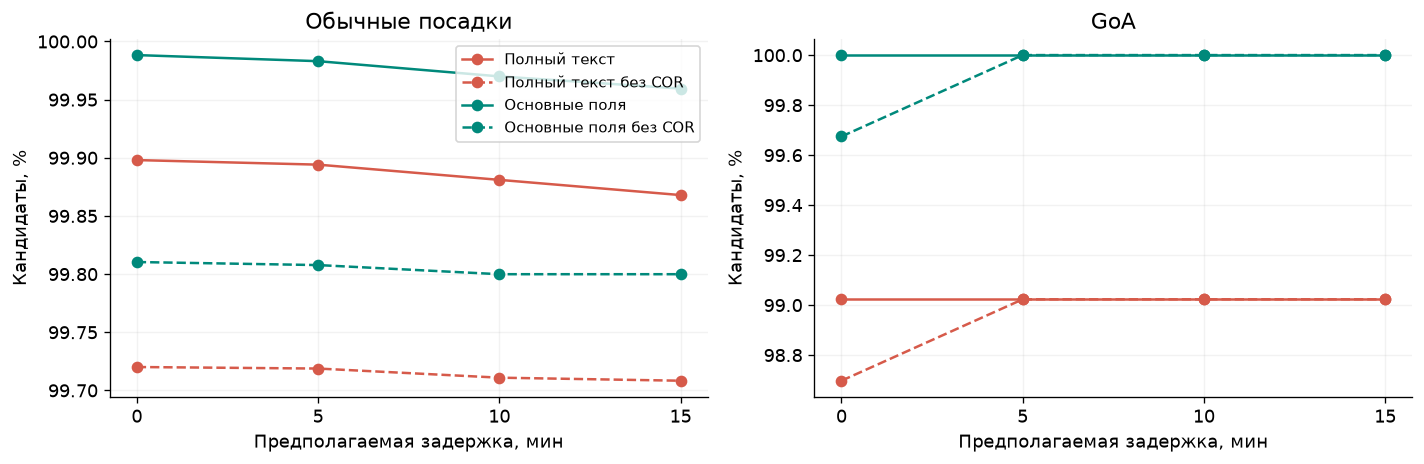

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,label in zip(axes,[False,True]):
    for quality,color in [('decoded_candidate',CORAL),('core_validated',GREEN)]:
        subset=summary.loc[summary.maximum_age_minutes.eq(60)&summary.GoA.eq(label)&summary.quality.eq(quality)]
        for exclude,style in [(False,'-'),(True,'--')]:
            series=subset.loc[subset.exclude_cor.eq(exclude)].sort_values('latency_minutes')
            ax.plot(series.latency_minutes,series.coverage_percent,style,marker='o',color=color,
                label=('Полный текст' if quality=='decoded_candidate' else 'Основные поля')+(' без COR' if exclude else ''))
    ax.set(title='GoA' if label else 'Обычные посадки',xlabel='Предполагаемая задержка, мин',ylabel='Кандидаты, %',xticks=[0,5,10,15])
axes[0].legend(fontsize=9)
save('08_latency_quality_coverage')


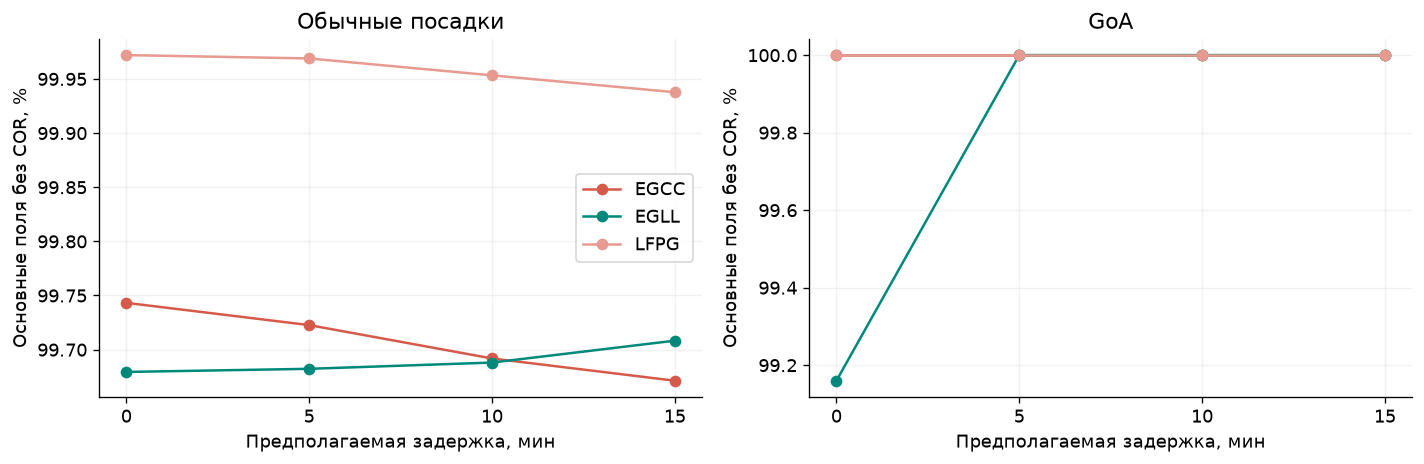

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,label in zip(axes,[False,True]):
    for airport in sorted(events.airport.unique()):
        subset=scenarios.loc[scenarios.maximum_age_minutes.eq(60)&scenarios.GoA.eq(label)&
            scenarios.quality.eq('core_validated')&scenarios.exclude_cor.eq(True)&scenarios.airport.eq(airport)]
        series=subset.groupby('latency_minutes')[['total','candidates']].sum()
        ax.plot(series.index,100*series.candidates/series.total,marker='o',label=airport)
    ax.set(title='GoA' if label else 'Обычные посадки',xlabel='Предполагаемая задержка, мин',ylabel='Основные поля без COR, %',xticks=[0,5,10,15])
axes[0].legend()
save('09_latency_airport_coverage')


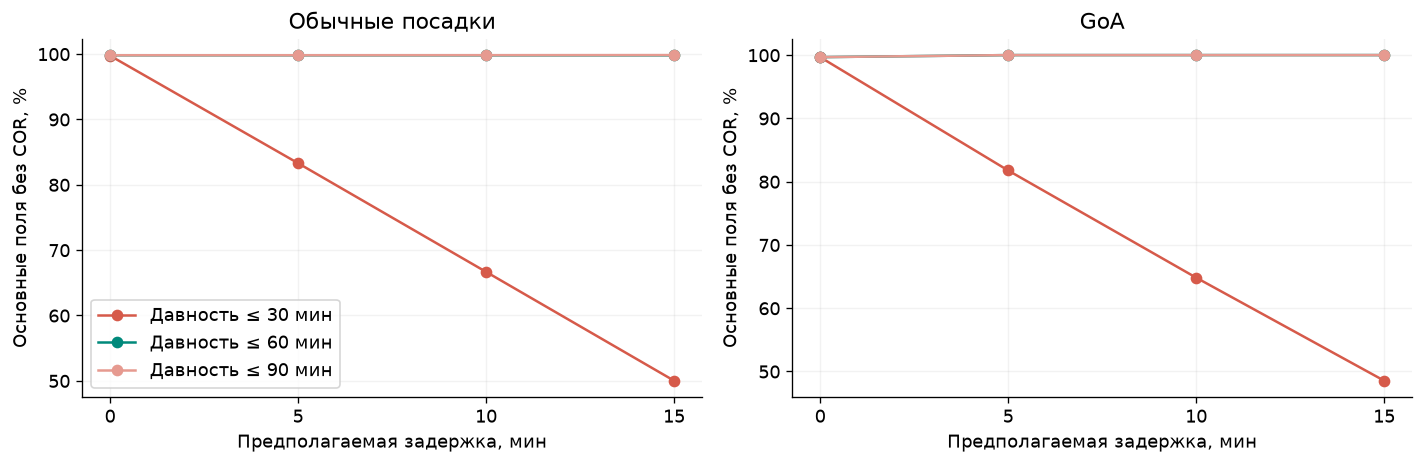

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,label in zip(axes,[False,True]):
    for limit in [30,60,90]:
        subset=summary.loc[summary.maximum_age_minutes.eq(limit)&summary.GoA.eq(label)&
            summary.quality.eq('core_validated')&summary.exclude_cor.eq(True)].sort_values('latency_minutes')
        ax.plot(subset.latency_minutes,subset.coverage_percent,marker='o',label=f'Давность ≤ {limit} мин')
    ax.set(title='GoA' if label else 'Обычные посадки',xlabel='Предполагаемая задержка, мин',ylabel='Основные поля без COR, %',xticks=[0,5,10,15])
axes[0].legend()
save('10_latency_age_limits')


## Границы результата и следующий этап

Проверка префикса относится только к наблюдаемым основным полям до QNH.
RE, WS, состояние ВПП и неразмеченный хвост требуют самостоятельного разбора;
никакие недостающие разделители не вставлялись. Значения пропусков остаются
пропусками. Даже положительный флаг не означает наличие каждого признака.
Покрытие без COR может увеличиваться с задержкой: повторный выбор меняет
сообщение, иногда на более старое без COR. Это не улучшение фактической погоды.
Шкалы покрытия на первых двух графиках увеличены для видимости малых различий.

Перед расширением следует проверить новые станции и форматы, затем повторить
полные месяцы с сохранением сырого ответа, SHA256 и времени загрузки. Критерий
выбора станций должен опираться на объем и разнообразие источника, а не GoA.
Историческое время публикации и доступность аэропорта к C40 остаются открытыми
вопросами. Массовая загрузка и обучение здесь не выполняются.


In [7]:
for path,digest in protected.items():
    assert sha(path)==digest
assert len(events)==manifest['rows'] and int(events.GoA.sum())==manifest['go_arounds']
assert not audit_core('EGCC 221050Z VRB03KT 9999 BKN015 02/00 Q1000 Q1001','EGCC',pd.Timestamp('2019-01-22T10:50Z'),{})[0]
assert not audit_core('EGCC 221050Z VRB03KT 9999 BKN015','EGCC',pd.Timestamp('2019-01-22T10:50Z'),{})[0]
assert not audit_core('EGCC 221050Z VRB03KT 9999 BKN015 Q1000','EGCC',pd.Timestamp('2019-01-22T10:50Z'),{})[0]
display(Markdown('**Проверено:** исходные файлы неизменны; нулевая задержка воспроизводит прежний выбор METAR; неоднозначный QNH и отсутствующие основные группы не принимаются.'))


**Проверено:** исходные файлы неизменны; нулевая задержка воспроизводит прежний выбор METAR; неоднозначный QNH и отсутствующие основные группы не принимаются.